In [1]:
# Tools for data processing and binary classification.
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score,
    precision_score, recall_score
)

In [2]:
from pathlib import Path

# Restore the guide's CSV in a fresh runtime.
if not Path('customer_purchase_binary.csv').exists():
    Path('customer_purchase_binary.csv').write_text('''Customer_ID,Visits_Last_28_Days,Cart_Visits_Last_28_Days,Avg_Session_Minutes,Purchased_Next_7_Days
C001,3,3,10.2,1
C002,4,1,1.9,0
C003,3,0,5.9,0
C004,4,2,1.3,0
C005,14,4,3.5,0
C006,4,1,4.8,0
C007,14,3,7.1,0
C008,,3,4.2,0
C009,4,2,10.1,0
C010,6,0,6.7,0
C011,10,1,3.3,0
C012,13,2,3.9,1
C013,8,3,7.5,1
C014,7,1,5.1,1
C015,6,3,1.9,0
C016,13,,3.2,0
C017,3,0,3.3,0
C018,18,6,10.4,1
C019,2,0,9.8,0
C020,13,2,1.8,0
C021,7,5,11.3,1
C022,19,14,4.8,1
C023,10,0,3.9,0
C024,9,8,14,1
C025,6,5,6.5,0
C026,8,6,7.8,0
C027,2,1,9.7,0
C028,11,1,8.2,0
C029,3,0,,0
C030,3,2,2,0
C031,12,6,5.5,1
C032,18,9,7.6,1
C033,8,5,7.3,0
C034,8,1,8.1,0
C035,9,1,2.3,0
C036,13,4,5.3,1
C037,13,7,1.7,0
C038,12,3,10.1,0
C039,8,0,9.1,0
C040,9,1,3.6,1
C041,10,4,8.7,0
C042,,0,10.7,0
C043,14,4,9.1,0
C044,10,5,4.9,0
C045,6,3,5.5,0
C046,8,6,6.3,0
C047,13,0,3.5,0
C048,8,1,1.1,0
C049,19,4,8.4,1
C050,11,4,7.1,0
C051,11,5,8.5,0
C052,7,3,1.2,0
C053,12,,6.8,0
C054,14,3,1.3,0
C055,12,3,12.5,1
C056,12,4,10.9,1
C057,14,9,3,1
C058,8,3,11.9,1
C059,5,3,12.1,1
C060,14,7,3.3,0
C061,2,0,8.5,0
C062,2,1,3.4,0
C063,13,2,7.1,0
C064,9,6,10.7,0
C065,7,2,8.9,0
C066,6,4,8.3,1
C067,12,0,,0
C068,2,1,9.5,0
C069,10,5,3.8,0
C070,6,3,3.4,0
C071,1,0,4.5,0
C072,12,4,5.2,1
C073,10,2,7.1,0
C074,11,2,5.8,0
C075,13,5,7.7,1
C076,13,0,4.8,0
C077,5,2,2.3,0
C078,10,4,7.1,0
C079,11,2,3.2,0
C080,4,0,3.3,0
C081,7,0,7,0
C082,3,1,10.2,1
C083,6,1,1.9,0
C084,2,0,4.9,0
C085,14,6,8.9,0
C086,2,0,6.7,0
C087,6,2,3.1,0
C088,8,4,10.6,0
C089,11,6,2.6,0
C090,20,12,7.6,1
C091,14,2,8.6,0
C092,13,6,2.6,0
C093,7,3,1.2,0
C094,3,1,6.6,0
C095,8,0,10.5,0
C096,4,1,7.1,0
C097,9,0,8,0
C098,5,2,3.1,1
C099,9,5,6.3,0
C100,6,3,3.3,0
C101,9,1,10.9,0
C102,11,4,9.1,0
C103,10,4,6.7,0
C104,5,,13.2,1
C105,8,4,4.2,0
C106,8,3,9.3,0
C107,5,1,1.7,0
C108,2,0,4.6,0
C109,2,0,10.8,0
C110,13,10,6.3,1
C111,7,1,3.9,0
C112,11,0,,0
C113,3,1,4.6,0
C114,4,1,7.9,0
C115,2,0,7.9,0
C116,14,2,6,0
C117,10,5,6.6,0
C118,10,1,4,0
C119,17,9,10.7,1
C120,2,1,8,0
C121,7,0,4.1,0
C122,10,1,10.4,0
C123,6,3,7.3,1
C124,11,3,2.3,0
C125,10,1,10.9,0
C126,7,2,1.8,0
C127,16,11,3.9,1
C128,14,4,1.1,0
C129,6,1,6.6,0
C130,13,7,4.1,0
C131,4,2,9.2,1
C132,6,2,2.7,0
C133,11,1,5.5,0
C134,2,2,10,0
C135,9,0,2.9,0
C136,4,0,6.2,0
C137,13,5,2.1,0
C138,14,5,1.7,0
C139,5,1,4,0
C140,11,3,8.8,0
C141,1,0,4.4,0
C142,8,0,8.7,0
C143,4,1,10.1,0
C144,10,4,9.7,0
C145,14,6,2.7,0
C146,3,0,8.3,0
C147,18,12,6,1
C148,1,0,6.1,0
C149,13,1,4.8,0
C150,9,0,4.2,0
C151,11,8,11.6,1
C152,4,2,3.7,1
C153,6,0,10,0
C154,2,2,9.2,0
C155,5,1,8.2,0
C156,6,1,9.8,0
C157,13,3,9.8,0
C158,10,0,9.3,0
C159,10,2,4.3,0
C160,3,1,5.6,0
C161,4,0,8.1,0
C162,2,1,10,0
C163,13,2,2.2,0
C164,10,1,4,1
C165,7,2,10.3,0
C166,4,0,10.2,0
C167,10,3,4.9,0
C168,7,6,6.9,0
C169,12,3,10.6,0
C170,12,2,3.6,0
C171,17,12,8.1,1
C172,7,1,1.4,0
C173,16,8,8.1,1
C174,6,0,1.7,0
C175,17,14,5.5,1
C176,4,0,9.7,0
C177,8,3,12.7,1
C178,4,2,3.8,0
C179,13,1,4.9,0
C180,17,6,4.9,1
C181,4,2,5.7,0
C182,13,3,7.3,0
C183,1,0,1.8,0
C184,4,1,8.2,0
C185,10,0,7.7,0
C186,11,3,4.4,0
C187,9,2,8.4,0
C188,7,1,11.6,1
C189,13,5,5.1,0
C190,10,0,10.7,0
C191,13,4,7.4,0
C192,5,2,2,0
C193,6,0,4,0
C194,14,10,7.3,0
C195,11,5,5.5,0
C196,10,1,9.8,0
C197,20,6,5.3,1
C198,5,0,8.9,0
C199,5,0,9.1,0
C200,11,6,9,0
C201,7,2,2.8,0
C202,13,2,2.8,0
C203,16,5,9.6,1
C204,10,6,2,0
C205,4,2,8.4,0
C206,7,0,4.9,0
C207,11,4,4.9,0
C208,6,0,8.5,0
C209,9,4,7.6,0
C210,3,1,5.8,0
C211,19,15,5.3,1
C212,10,9,3,1
C213,13,4,2.4,0
C214,9,9,2.6,0
C215,9,6,6.6,0
C216,10,7,9.5,0
C217,11,4,9.5,0
C218,10,3,5.1,0
C219,11,4,10.9,0
C220,6,3,4,0
C221,10,5,4.5,0
C222,1,0,2.3,0
C223,6,0,4.9,0
C224,9,2,1.3,0
C225,5,2,4.9,0
C226,2,0,3.6,0
C227,1,1,9.5,0
C228,12,2,9,0
C229,7,0,8.5,0
C230,13,7,9.7,1
C231,7,0,8.8,0
C232,10,5,10.6,0
C233,6,1,8.1,0
C234,12,12,8.2,0
C235,6,0,4.2,0
C236,1,1,5.9,0
C237,10,2,7.1,1
C238,18,9,11.7,1
C239,9,4,3.9,0
C240,5,1,10.1,0
C241,15,9,10.7,1
C242,5,1,2.2,0
C243,3,1,7.9,0
C244,11,2,9.7,0
C245,13,12,13.3,1
C246,4,0,7.9,0
C247,14,5,7.4,0
C248,12,0,10.6,0
C249,9,3,12,1
C250,5,0,3.8,0
C251,4,0,8.4,0
C252,14,7,6.3,1
C253,3,0,4.6,0
C254,13,5,4.6,0
C255,5,2,9.6,0
C256,3,0,2.5,0
C257,18,8,4.8,1
C258,4,2,5.6,1
C259,18,4,12.6,1
C260,15,3,4.9,1
C261,9,1,8.4,0
C262,9,2,2.1,0
C263,5,0,7.1,1
C264,11,2,5.1,0
C265,8,2,1.9,0
C266,1,1,3.9,0
C267,13,0,2.7,0
C268,10,3,6.5,0
C269,14,10,8.3,0
C270,1,1,4.5,0
C271,10,1,1.9,0
C272,11,2,6.5,0
C273,14,0,3.6,0
C274,5,0,7.9,1
C275,5,1,4.6,1
C276,13,4,7.3,0
C277,4,2,1.2,0
C278,5,0,1.7,0
C279,11,1,9,0
C280,7,1,8.9,0
C281,12,1,10.2,0
C282,3,2,3.3,0
C283,5,0,1.4,0
C284,20,10,13.1,1
C285,2,1,7.1,0
C286,4,4,7.5,1
C287,5,2,9.7,0
C288,4,1,7,0
C289,4,1,10.1,0
C290,7,1,9.2,0
C291,13,1,4.1,0
C292,14,6,9.6,0
C293,9,4,4.9,0
C294,4,2,6.4,0
C295,3,0,8.6,0
C296,3,0,1.8,0
C297,10,2,9.5,0
C298,10,4,3.8,0
C299,19,9,7.6,1
C300,10,1,8.4,1
C301,10,2,8.6,0
C302,12,2,13.3,1
C303,13,6,7.1,1
C304,2,0,5.6,0
C305,3,1,2.9,0
C306,6,1,6.9,0
C307,12,0,6.2,0
C308,10,1,8.6,0
C309,19,4,7.6,1
C310,7,1,5.1,0
C311,11,7,9.1,0
C312,10,6,3.6,0
C313,2,0,10.2,0
C314,8,2,5.8,0
C315,6,1,3.4,0
C316,9,3,1.2,0
C317,11,1,7.1,0
C318,7,1,7.5,0
C319,11,3,8.4,0
C320,7,0,5.9,0
C321,5,0,1.2,0
C322,6,4,12.5,1
C323,2,0,3.1,0
C324,11,0,4.5,1
C325,3,1,2.1,0
C326,7,0,5.3,0
C327,7,1,1.9,0
C328,7,4,9.4,1
C329,4,1,8.9,0
C330,1,0,5,0
C331,10,1,3.9,0
C332,1,1,8.7,0
C333,11,3,1.9,0
C334,6,0,9,1
C335,15,8,11.2,1
C336,14,5,5.1,0
C337,1,0,7.7,0
C338,14,3,7.8,0
C339,13,2,6.6,0
C340,13,11,1.5,0
C341,7,1,4.6,0
C342,10,3,4.5,0
C343,5,2,8.4,1
C344,7,3,8,0
C345,4,0,2.5,0
C346,4,2,5.9,0
C347,6,3,6.5,0
C348,8,7,3.2,0
C349,14,8,8.6,1
C350,6,2,10.2,0
C351,8,0,8.6,0
C352,14,4,3.4,1
C353,14,1,5.8,0
C354,10,0,4.8,0
C355,4,1,5.5,1
C356,7,1,7,0
C357,12,2,7.4,0
C358,9,5,1.6,0
C359,9,2,9.1,1
C360,2,0,8,0
C361,7,3,8.2,0
C362,12,11,7.9,1
C363,2,0,10.3,0
C364,5,3,1.8,0
C365,4,0,1.4,0
C366,11,1,10.7,0
C367,13,3,8.5,0
C368,9,1,9,0
C369,11,0,3.2,0
C370,5,2,4.1,1
C371,9,3,3.9,0
C372,8,2,8.4,0
C373,12,10,6.5,1
C374,11,7,4.7,0
C375,14,10,8,0
C376,1,0,3.9,0
C377,8,2,3.3,1
C378,6,3,4.9,0
C379,14,6,4.9,0
C380,13,3,6.9,0
C381,6,1,4.4,0
C382,6,3,1.5,0
C383,8,2,9.1,0
C384,8,3,4.5,0
C385,1,0,5.7,0
C386,12,2,1.9,0
C387,13,3,9.5,0
C388,18,17,10.5,1
C389,5,1,4.1,0
C390,10,0,9.8,0
C391,4,3,9.7,0
C392,7,1,9.9,0
C393,9,5,9.9,1
C394,17,9,4.6,1
C395,9,1,5.1,0
C396,5,4,10.2,0
C397,5,0,9.6,0
C398,6,0,10.1,0
C399,2,0,1.1,0
C400,1,0,6.4,0
C401,3,3,9,0
C402,2,0,10.6,0
C403,5,2,8.4,0
C404,10,3,1.1,0
C405,14,4,9.6,0
C406,13,7,12.2,1
C407,8,3,3.6,0
C408,8,6,1,0
C409,10,8,4,1
C410,11,2,7.3,0
C411,1,0,4.3,0
C412,4,0,4.5,0
C413,1,1,5.3,0
C414,6,3,10.7,0
C415,5,3,9.7,0
C416,1,1,6.1,0
C417,5,1,3.7,0
C418,10,7,4.8,0
C419,12,5,8.7,0
C420,4,1,3.3,0
C421,9,2,6.3,0
C422,6,4,2.1,0
C423,5,2,3.4,0
C424,13,5,3.2,0
C425,4,1,3.9,0
C426,5,2,8.9,0
C427,13,2,7.4,0
C428,1,0,8.2,0
C429,4,3,2.4,0
C430,1,0,3.7,0
C431,15,8,10.6,1
C432,2,0,7.8,0
C433,3,2,3.5,1
C434,12,3,5.5,0
C435,12,7,2.7,0
C436,3,0,6.4,0
C437,2,1,1.1,0
C438,8,3,1.6,0
C439,14,11,6.4,0
C440,10,1,8.5,0
C441,13,2,9.1,0
C442,3,0,4.1,0
C443,19,8,7.8,1
C444,10,2,12.3,1
C445,5,4,10.3,0
C446,14,3,5.9,0
C447,9,5,7.9,1
C448,7,0,7,0
C449,7,4,11,1
C450,3,2,5.6,0
C451,9,6,3.5,0
C452,10,5,5.9,0
C453,1,0,5,0
C454,12,1,1.2,0
C455,3,0,6,0
C456,2,0,2.7,0
C457,1,0,10.5,0
C458,10,2,3.6,0
C459,14,5,3.2,0
C460,10,4,3.8,0
C461,8,2,7.3,0
C462,6,2,6.1,0
C463,19,13,6,1
C464,5,1,1.8,0
C465,3,2,5.9,1
C466,17,11,12.2,1
C467,12,10,2.7,0
C468,10,4,3.1,0
C469,6,0,10.4,0
C470,1,0,2.3,0
C471,3,2,7.7,0
C472,11,2,6.7,0
C473,11,3,3.7,0
C474,3,1,3,0
C475,14,7,4.5,0
C476,6,4,8,1
C477,11,3,4.9,0
C478,12,3,7.5,0
C479,9,8,6.1,0
C480,16,9,9.3,1
C481,8,3,8.5,0
C482,14,3,8.8,0
C483,4,1,6.9,1
C484,6,5,1.7,0
C485,11,1,7.5,0
C486,1,0,6.2,0
C487,11,3,11.6,1
C488,15,11,11.9,1
C489,10,2,5.1,0
C490,2,0,10.4,0
C491,7,1,10.9,0
C492,2,1,8,0
C493,3,1,5.8,0
C494,4,1,7,0
C495,8,1,1.8,0
C496,10,4,6.8,1
C497,10,1,3.7,0
C498,8,0,4.6,0
C499,8,1,5.7,0
C500,16,0,10.9,1
C003,3,0,5.9,0
C020,13,2,1.8,0
C058,8,3,11.9,1
C106,8,3,9.3,0
''', encoding='utf-8')

raw = pd.read_csv("customer_purchase_binary.csv")
display(raw.head())

,Customer_ID,Visits_Last_28_Days,Cart_Visits_Last_28_Days,Avg_Session_Minutes,Purchased_Next_7_Days
0,C001,3.0,3.0,10.2,1
1,C002,4.0,1.0,1.9,0
2,C003,3.0,0.0,5.9,0
3,C004,4.0,2.0,1.3,0
4,C005,14.0,4.0,3.5,0


In [3]:
# Check structure and obvious data-quality issues.
print("Raw shape:", raw.shape)
raw.info()
print("Missing values:")
print(raw.isna().sum())
print("Exact repeated rows:", raw.duplicated().sum())

Raw shape: (504, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 504 entries, 0 to 503
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Customer_ID               504 non-null    object 
 1   Visits_Last_28_Days       502 non-null    float64
 2   Cart_Visits_Last_28_Days  501 non-null    float64
 3   Avg_Session_Minutes       501 non-null    float64
 4   Purchased_Next_7_Days     504 non-null    int64  
dtypes: float64(3), int64(1), object(1)
memory usage: 19.8+ KB
Missing values:
Customer_ID                 0
Visits_Last_28_Days         2
Cart_Visits_Last_28_Days    3
Avg_Session_Minutes         3
Purchased_Next_7_Days       0
dtype: int64
Exact repeated rows: 4


In [4]:
# Remove exact repeated customer records before splitting.
data = raw.drop_duplicates().reset_index(drop=True)
print("Unique customer rows:", len(data))

# Inputs were observed before the purchase-label window.
features = [
    "Visits_Last_28_Days",
    "Cart_Visits_Last_28_Days",
    "Avg_Session_Minutes"
]
X = data[features].copy()
y = data["Purchased_Next_7_Days"].copy()

Unique customer rows: 500


In [5]:
# Keep both classes represented in each partition.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print("Training labels:")
print(y_train.value_counts().sort_index())
print("Test labels:")
print(y_test.value_counts().sort_index())

Training rows: 375
Test rows: 125
Training labels:
Purchased_Next_7_Days
0    300
1     75
Name: count, dtype: int64
Test labels:
Purchased_Next_7_Days
0    100
1     25
Name: count, dtype: int64


,Visits_Last_28_Days,Cart_Visits_Last_28_Days,Avg_Session_Minutes
count,373.00,372.00,373.0
mean,8.55,2.93,6.4
std,4.48,3.07,3.0
min,1.00,0.00,1.0
25%,5.00,1.00,4.0
50%,9.00,2.00,6.4
75%,12.00,4.00,8.8
max,20.00,17.00,13.3


Visits_Last_28_Days         2
Cart_Visits_Last_28_Days    3
Avg_Session_Minutes         2
dtype: int64


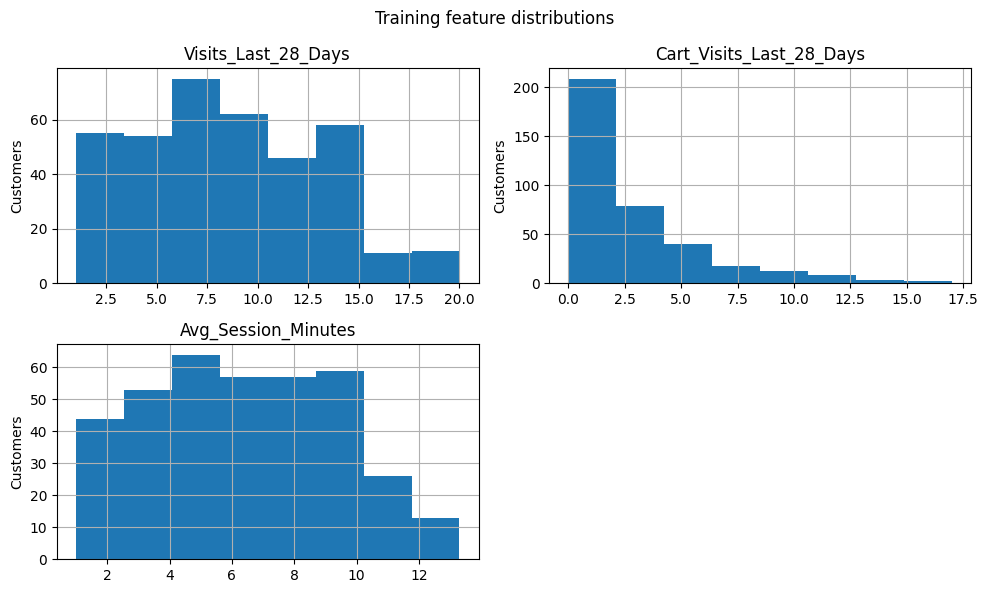

In [6]:
# Explore training features, keeping the test set aside.
display(X_train.describe().round(2))
print(X_train.isna().sum())

axes = X_train.hist(bins=8, figsize=(10, 6))
for ax in axes.flat:
    ax.set_ylabel("Customers")
plt.suptitle("Training feature distributions")
plt.tight_layout()
plt.show()

Purchased_Next_7_Days
0    300
1     75
Name: count, dtype: int64


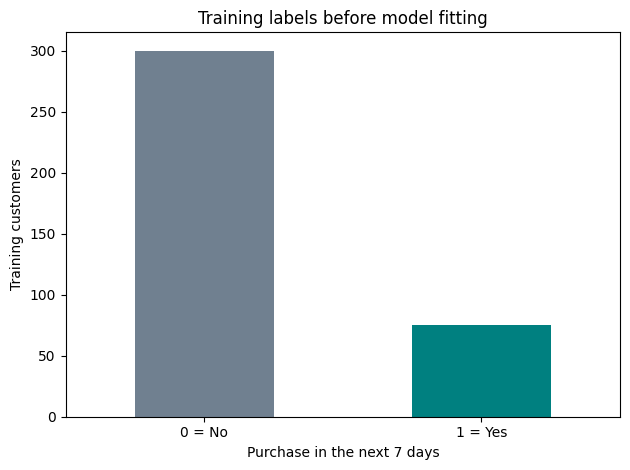

In [7]:
# Inspect the class imbalance in the training data.
counts = y_train.value_counts().sort_index()
print(counts)
counts.plot(kind="bar", color=["slategray", "teal"])
plt.xticks([0, 1], ["0 = No", "1 = Yes"], rotation=0)
plt.xlabel("Purchase in the next 7 days")
plt.ylabel("Training customers")
plt.title("Training labels before model fitting")
plt.tight_layout()
plt.show()

In [8]:
# Apply the same fixed, row-based rule to both sets.
X_train = X_train.copy()
X_test = X_test.copy()
for part in [X_train, X_test]:
    part["Cart_Rate"] = (
        part["Cart_Visits_Last_28_Days"]
        / part["Visits_Last_28_Days"]
    )

model_features = [
    "Visits_Last_28_Days", "Avg_Session_Minutes", "Cart_Rate"
]
X_train = X_train[model_features]
X_test = X_test[model_features]
display(X_train.head().round(2))

,Visits_Last_28_Days,Avg_Session_Minutes,Cart_Rate
290,13.0,4.1,0.08
177,4.0,3.8,0.50
469,1.0,2.3,0.00
461,6.0,6.1,0.33
472,11.0,3.7,0.27


In [9]:
# Fit every learned step using training data only.
model = Pipeline([
    ("fill_missing", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
    ("classifier", LogisticRegression(
        class_weight="balanced", max_iter=1000,
        random_state=42
    ))
])
model.fit(X_train, y_train)
print("The training pipeline is fitted.")

The training pipeline is fitted.


In [10]:
# Predict the held-out customers without refitting.
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)

print("Accuracy:", round(accuracy, 3))
print("Precision for Yes:", round(precision, 3))
print("Recall for Yes:", round(recall, 3))

Accuracy: 0.792
Precision for Yes: 0.486
Recall for Yes: 0.72


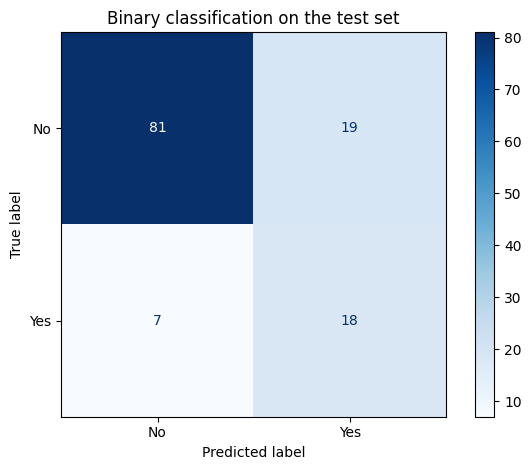

In [11]:
# Rows are actual labels; columns are predicted labels.
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, labels=[0, 1],
    display_labels=["No", "Yes"],
    cmap="Blues", values_format="d"
)
plt.title("Binary classification on the test set")
plt.tight_layout()
plt.show()

,Accuracy,Recall_Yes
Always No,0.800,0.00
Logistic regression,0.792,0.72


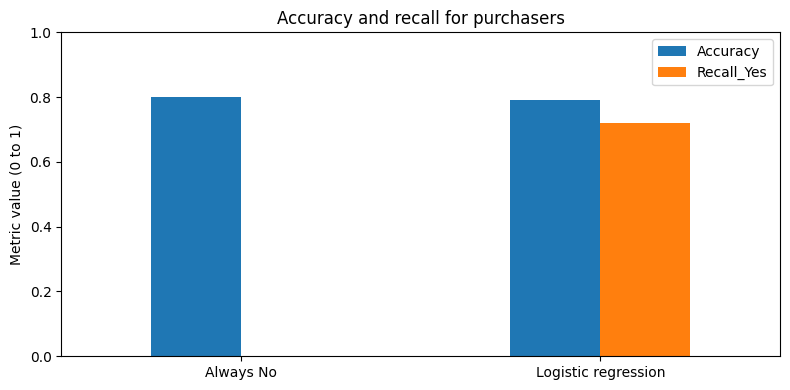

In [12]:
# Compare with a baseline that always predicts No.
baseline_pred = [0] * len(y_test)
comparison = pd.DataFrame({
    "Accuracy": [
        accuracy_score(y_test, baseline_pred),
        accuracy_score(y_test, y_pred)
    ],
    "Recall_Yes": [
        recall_score(y_test, baseline_pred),
        recall_score(y_test, y_pred)
    ]
}, index=["Always No", "Logistic regression"])
display(comparison.round(3))

comparison.plot(kind="bar", ylim=(0, 1), rot=0,
                figsize=(8, 4))
plt.ylabel("Metric value (0 to 1)")
plt.title("Accuracy and recall for purchasers")
plt.tight_layout()
plt.show()

In [13]:
# Inspect a few held-out predictions.
results = pd.DataFrame({
    "Customer_ID": data.loc[X_test.index, "Customer_ID"],
    "Actual": y_test,
    "Predicted": y_pred,
    "Purchase_probability": model.predict_proba(X_test)[:, 1]
})
display(results.head(10).round(3))

,Customer_ID,Actual,Predicted,Purchase_probability
79,C080,0,0,0.064
256,C257,1,1,0.769
69,C070,0,0,0.224
161,C162,0,0,0.368
272,C273,0,0,0.324
385,C386,0,0,0.242
72,C073,0,0,0.426
20,C021,1,1,0.756
370,C371,0,0,0.286
414,C415,0,1,0.541


### 1. Explain the preprocessing choices

The raw table had 504 rows, including 4 exact repeats. Removing them before splitting left 500 unique rows. The raw missing-value check found 2 missing visit counts, 3 missing cart-visit counts, and 3 missing average session times. Customer IDs and purchase labels had no missing values. I excluded Customer_ID from the features and used a stratified split with 375 training rows and 125 test rows. I calculated Cart_Rate as cart visits divided by visits for each row in both sets. The pipeline filled missing model inputs with training medians and standardized them using training means and standard deviations. Fitting both steps only on the training set prevented information from held-out customers from influencing preprocessing. The pipeline applied the same fitted transformations at test time.

### 2. Interpret the binary predictions

For Purchase = 1, the test set had **18 true positives** (customers predicted to buy who bought), **19 false positives** (customers predicted to buy who did not), and **7 false negatives** (customers predicted not to buy who bought). The store correctly identified 18 purchasers, flagged 19 non-purchasers as likely buyers, and missed 7 purchasers. The other 81 customers were correctly predicted as non-purchasers.

### 3. Compare the model with the baseline

Always No had **80.0% accuracy** and **0.0% purchaser recall**. Logistic regression had **79.2% accuracy** and **72.0% purchaser recall**, finding 18 of 25 purchasers versus zero for Always No. Accuracy alone hides the baseline’s failure to find purchasers because 100 of the 125 test customers did not buy. Logistic regression reduced missed purchasers from 25 to 7 while producing 19 false positives, which explains the 0.8 percentage-point drop in accuracy.